<a href="https://colab.research.google.com/github/atanyeri/econ5200-lab11-did/blob/main/lab_ch11_diagnostic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 11: Identification & Difference-in-Differences — Diagnosing the Failure
## ECON 5200: Causal Machine Learning & Applied Analytics
### Diagnostic Lab | 85 min Core + 40 min AI + 30 min Extension

---

**Learning Objectives:**
- Reproduce the canonical two-by-two on the original Card & Krueger data
- Show that parallel trends is an assumption, and that a pre-trend test does not establish it
- Demonstrate that two-way fixed effects under staggered adoption can return the wrong sign, and take it apart into the two-by-two comparisons it averages
- Diagnose standard errors that ignore shocks shared within a state
- Read and run a difference-in-differences module (`src/did_utils.py`) that never uses an already-treated unit as a control
- Check a Goodman-Bacon decomposition written by AI against your own, and revise the prompt that produced it

**Dataset:** Card & Krueger (1994) NJ/PA fast-food survey from David Card's archive, plus simulated panels with known effects

**Format:** Each diagnosis hands you a result that is wrong (an estimate in Diagnoses 1 and 2, a
standard error in Diagnosis 3) and asks what happened before it tells you. Write your diagnosis
before running the reveal cell.

**Deliverable:** your written diagnoses (Diagnoses 1, 2 and 3) and your four answers on the AI's
decomposition.

**Time:** Core (85 min) + AI (40 min) + Extension (optional, 30 min) + Challenge (optional, ungraded)

With setup, the README and the GitHub submission, plan on about 2¼ hours, most of it after class. The optional Extension adds about 30 minutes.

**AI in the manual parts:** you may ask Colab to *explain* an error or a line of code (click **Explain error**, or select a line and ask Gemini to explain it). Do not ask it to write or fix code, and turn off AI code completion while you work on those parts. AI-assisted coding is allowed only where this lab says so.

---

> ### What you write, and what you run
>
> **You write, in text cells:**
> - **Diagnoses 1, 2 and 3:** two, three and two short answers. Write each before you run the reveal that follows it.
> - **The AI Expansion:** version 2 of the given prompt, revised once, after you find what version 1 left the AI to guess. Then four short answers: your revision, the check against your own numbers, the key lines in your own words, and when AI is worth using for this.
> - **Extension (optional):** four interpretation answers.
>
> **You run and read:** every code cell in the Warm-Up, the diagnoses and Ship It, and the AI section's setting and check cells. They are the analyst's estimates, the reveals, and a finished module, `did_utils.py`, which is working code to read, not to retype. Read each cell before you run it: the questions ask about what it prints. The AI's function is pasted, not typed, and the code itself is not graded; your answers about it are.
>
> **Code you write yourself (none of it required this week):**
> - the Extension's event-study chart, with two pre-period estimates you compute: about 40 lines;
> - the take-home Challenge, honest bounds on Diagnosis 1's panel, from a five-step outline.

In [1]:
# GIVEN — run as-is
# Setup: libraries and folders
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

Path("figures").mkdir(exist_ok=True)   # Diagnosis 1 saves its chart here
Path("src").mkdir(exist_ok=True)       # Ship It writes its module into this folder

RANDOM_STATE = 42    # each simulation below starts its own generator from this seed
print("Setup complete.")

Setup complete.


## Warm-Up: The Canonical Two-by-Two, On The Original Data (12 min)

Before diagnosing failures, establish that the method works when its assumption holds. On
1 April 1992 New Jersey raised its minimum wage from \$4.25 to \$5.05; Pennsylvania did not.
Card and Krueger surveyed the same fast-food restaurants in both states before and after.

**Reading the code.** The first cell downloads Card's zip file and reads `public.dat`, naming its columns from the codebook (you will not need to write the `re.findall` pattern); a lone `.` in the file means missing, and summing True/False values counts the Trues.

In the second cell, `ck.groupby("STATE")[[...]].mean()` gives one row of means per state, and
`.loc[1]` picks the row labelled 1. In the prints, `{x:<12}` left-aligns in 12 characters,
`{x:>9.2f}` right-aligns in 9 with two decimals, and `"-" * 39` is a line of 39 dashes.

In [2]:
# GIVEN — run as-is
# Card & Krueger (1994), from David Card's own archive
import io
import re
import urllib.request
import zipfile

raw = urllib.request.urlopen(
    "https://davidcard.berkeley.edu/data_sets/njmin.zip", timeout=60).read()
z = zipfile.ZipFile(io.BytesIO(raw))

# public.dat is fixed-width numbers; the codebook supplies a name for each column
names = re.findall(r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d",
                   z.read("codebook").decode("latin-1"), re.M)
ck = pd.read_csv(io.BytesIO(z.read("public.dat")), sep=r"\s+", header=None,
                 names=names, na_values=["."])

# Full-time-equivalent employment, Card & Krueger's outcome: full-timers, managers and
# half of part-timers, in each wave (a 2 at the end of a name marks the second wave)
ck["fte_before"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]
ck["fte_after"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]

print(f"{len(ck)} restaurants: {int((ck.STATE == 1).sum())} NJ, "
      f"{int((ck.STATE == 0).sum())} PA")

410 restaurants: 331 NJ, 79 PA


In [3]:
# GIVEN — run as-is
# The two-by-two, by hand: mean employment by state, before and after
means_by_state = ck.groupby("STATE")[["fte_before", "fte_after"]].mean()
nj, pa = means_by_state.loc[1], means_by_state.loc[0]    # STATE is 1 for New Jersey, 0 for Pennsylvania

did = (nj.fte_after - nj.fte_before) - (pa.fte_after - pa.fte_before)

print(f"{'':<12}{'before':>9}{'after':>9}{'change':>9}")
print("-" * 39)
print(f"{'NJ (treated)':<12}{nj.fte_before:>9.2f}{nj.fte_after:>9.2f}"
      f"{nj.fte_after - nj.fte_before:>9.2f}")
print(f"{'PA (control)':<12}{pa.fte_before:>9.2f}{pa.fte_after:>9.2f}"
      f"{pa.fte_after - pa.fte_before:>9.2f}")
print("-" * 39)
print(f"{'DiD':<12}{'':>18}{did:>9.2f}")

               before    after   change
---------------------------------------
NJ (treated)    20.44    21.03     0.59
PA (control)    23.33    21.17    -2.17
---------------------------------------
DiD                                2.75


**Expected output:** 410 restaurants, 331 in New Jersey and 79 in Pennsylvania. In the table,
New Jersey goes from 20.44 to 21.03 full-time equivalents (+0.59) and Pennsylvania from 23.33
to 21.17 (−2.17), so the DiD is **+2.75**. Card and Krueger's published figure is +2.76.
Employment rose in the state that raised its minimum wage, relative to the state that did not.

The second difference is doing the work. Employment fell in Pennsylvania and rose a little in
New Jersey. New Jersey started 2.89 below Pennsylvania, and any story that explains that level
difference is already differenced away.

---

## Diagnosis 1: The Assumption That Cannot Be Tested (15 min)

Below, a treated group and a control group. The treatment does nothing at all — the true
effect is exactly zero. The DiD estimate is large and significant.

**Reading the code.** The loop builds the panel one row at a time: 200 units over 12 periods,
each row a tuple appended to `rows`, and `pd.DataFrame(rows, columns=[...])` turns the list of
tuples into a table, one tuple per row. `n_units // 2` is whole-number division (100), so the
first 100 units are treated, and `int(treated)` stores True and False as 1 and 0.
`a if condition else b` is `a` when the condition holds and `b` otherwise.

`smf.ols("y ~ treated * post", data=panel)` fits a regression written as a formula: the
outcome left of `~`, the regressors right of it. `treated * post` means `treated`, `post` and
their product, which statsmodels names `treated:post`. That product's coefficient is the DiD
estimate, and `.params["treated:post"]` and `.pvalues["treated:post"]` pick it out by name.

In [4]:
# THE ANALYST'S CODE — run as-is, then diagnose it
# A two-by-two DiD on a panel where the policy does nothing
T_PRE, T_POST = 6, 6
n_units = 200
r = np.random.default_rng(RANDOM_STATE)

rows = []
for i in range(n_units):
    treated = i < n_units // 2
    fe = r.normal(0, 1)                        # the unit's own level
    slope = 0.30 if treated else 0.10          # how fast the unit's outcome drifts each period
    for t in range(T_PRE + T_POST):
        post = t >= T_PRE
        y = fe + slope * t + r.normal(0, 0.4)     # no treatment term anywhere
        rows.append((i, int(treated), t, int(post), y))

panel = pd.DataFrame(rows, columns=["unit", "treated", "t", "post", "y"])

fit = smf.ols("y ~ treated * post", data=panel).fit()
print(f"DiD estimate: {fit.params['treated:post']:.3f}   p = {fit.pvalues['treated:post']:.4f}")
print("TRUE effect:  0.000")

DiD estimate: 1.148   p = 0.0000
TRUE effect:  0.000


### YOUR DIAGNOSIS

1. The regression is correctly specified for a two-by-two DiD, and the data contain no treatment effect. Where does the estimate come from?
2. Predict what a pre-trend test would show here, and whether passing one would have saved you.

1. The treated units drift upward faster (0.30 vs 0.10 per period), so parallel trends is violated by construction. The unit fixed effects cancel in the differencing, but the slope difference does not. The pre and post periods have mean times of 2.5 and 8.5, which is a six period gap. The extra drift of 0.20 per period produces about 0.20 * 6 = 1.2, closely resembling the 1.148 estimate up to noise. With 200 units the standard errors are small, so the spurious effect looks significant.

2. It would reject, because using only the pre-periods, the treated*t coefficient would be near 0.20 with a small p-value, so the divergence is visible before any policy exists. However, a pass would not have helped here. Parallel trends is a claim about the post-period counterfactual, which pre-period data can't verify.

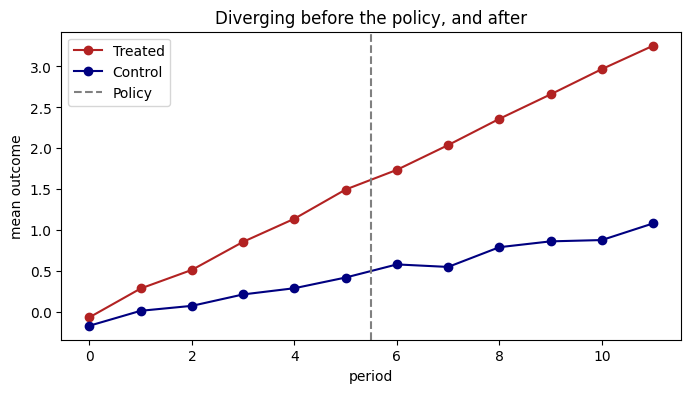

In [25]:
# GIVEN — run as-is
# The reveal: plot the group means, before and after the policy
# .unstack() turns the groups into columns: one row per period, one column per group
means = panel.groupby(["t", "treated"])["y"].mean().unstack()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(means.index, means[1], marker="o", color="firebrick", label="Treated")
ax.plot(means.index, means[0], marker="o", color="navy", label="Control")
ax.axvline(T_PRE - 0.5, color="grey", linestyle="--", label="Policy")
ax.set_xlabel("period")
ax.set_ylabel("mean outcome")
ax.set_title("Diverging before the policy, and after")
ax.legend()
plt.savefig("figures/ch11_parallel_trends.png", dpi=150, bbox_inches="tight")
plt.show()

In [6]:
# GIVEN — run as-is
# The reveal, continued: the pre-trend test, on the six periods before the policy
pre = panel[panel["t"] < T_PRE]
pre_fit = smf.ols("y ~ treated * t", data=pre).fit()   # treated:t is the difference in slopes
print(f"Pre-period difference in slopes: {pre_fit.params['treated:t']:.3f}"
      f"   p = {pre_fit.pvalues['treated:t']:.4f}")

Pre-period difference in slopes: 0.194   p = 0.0000


**Reading the reveal.** The chart shows the two groups pulling apart before the policy as well
as after it. The pre-trend test agrees: the treated group's slope is 0.194 a period steeper
before the policy, with a p-value that prints as 0.0000, meaning below 0.00005.

Here the pre-trend test fires, and would have saved you. That is the good case, not a
guarantee. A test that fires is informative. A test that does not fire does not establish
parallel trends: the trends may really be parallel, or you may have lacked the power to see a
difference.

---

## Diagnosis 2: The Forbidden Comparison (30 min)

Now staggered adoption, where policies arrive in waves. Two-way fixed effects (TWFE) is the
standard response and one of the most-run regressions in economics.

In the panel below **every true treatment effect is positive**, ranging from +1 to +15.

**Reading the code.** `staggered_panel` takes a dict of cohorts, each a name and the period in
which that cohort is first treated, and builds 60 units per cohort over 18 periods. `D` is 1
once a unit is treated, and `true_eff` is the effect built into its outcome. In the formula,
`C(unit)` and `C(t)` turn the unit and the period into one dummy for each value: those are the
two sets of fixed effects, and the coefficient on `D` is the TWFE estimate.
`sp.loc[sp["D"] == 1, "true_eff"]` keeps the true effects of the treated rows.

In [7]:
# THE ANALYST'S CODE — run as-is, then diagnose it
# Staggered adoption: two cohorts of 60 units, treated at periods 3 and 12
def staggered_panel(cohorts, growth=1.0, T=18, n_per=60, seed=RANDOM_STATE):
    """A panel of n_per units per cohort; cohorts maps a name to its first treated period."""
    r = np.random.default_rng(seed)
    rows = []
    for cohort, g in cohorts.items():
        for i in range(n_per):
            fe = r.normal(0, 1)
            for t in range(T):
                eff = growth * (t - g + 1) if t >= g else 0.0
                rows.append((f"{cohort}{i}", cohort, g, t, int(t >= g), eff,
                             fe + 0.1 * t + eff + r.normal(0, 0.5)))
    return pd.DataFrame(rows, columns=["unit", "cohort", "g", "t", "D", "true_eff", "y"])

sp = staggered_panel({"early": 3, "late": 12})
twfe = smf.ols("y ~ D + C(unit) + C(t)", data=sp).fit()

treated_eff = sp.loc[sp["D"] == 1, "true_eff"]
print("Cohorts: early adopts at t=3, late at t=12. No never-treated group.")
print(f"True effects on the treated: min {treated_eff.min():.1f}, "
      f"max {treated_eff.max():.1f}, mean {treated_eff.mean():.2f}")
print()
print(f"TWFE estimate of the treatment effect: {twfe.params['D']:.2f}")

Cohorts: early adopts at t=3, late at t=12. No never-treated group.
True effects on the treated: min 1.0, max 15.0, mean 6.71

TWFE estimate of the treatment effect: -0.99


### YOUR DIAGNOSIS

1. Every true effect is positive and the TWFE estimate is negative. Goodman-Bacon shows TWFE is a weighted average of every available two-by-two. With two cohorts and no never-treated units, list the comparisons available, say which one is illegitimate and why, and explain how it can pull the average below zero.
2. State the condition on the treatment effects under which TWFE would have been fine here.
3. Predict what happens to the estimate if you add a group of never-treated units.

1. With two cohorts and no never-treated unit, TWFE averages three two-by-twos: 1) early vs late, with late as the not-yet treated control; 2) late vs early, with early as the already-treated control; and the within-cohort pre/post comparison against the other group's unchanged status, which is part of early vs late. Late vs early is the illegitimate one, as its control is already treated and its outcome keeps rising with its own growing effect (1 per period). The DiD reads the rise as the counterfactual trend, so the late cohort looks like it fell relative to control. Because effects are highly dynamic, this negative term outweighs the clean comparison and drags the average to -0.99.

2. TWFe is fine if treatment effects are constant across cohorts and over time since treatment. Then an already-treated control shifts by a constant that differences out, so every two-by-two estimates the same effect.

3. The estimate would rise sharply toward the real average, most likely close to the positive mean, though still not exactly. A never-treated group supplies clean controls in every period, so the forbidden comparison gets a smaller share of the weight. It would not vanish entirely, since early and late cohorts would still compare to each other, so the estimate would remain a little biased downward.

**The reveal, part 1: what TWFE averaged.** With two cohorts and no never-treated units, TWFE
can form two two-by-twos, each the same difference of differences as the Warm-Up's, on cohort
means. In the **clean** one, the early cohort (treated at 3) is compared with the late cohort
while the late cohort is still untreated: periods 0 to 11. In the **forbidden** one, the late
cohort (treated at 12) is compared with the early cohort, which is already treated: periods 3
to 17.

Goodman-Bacon (2021) derived the weight TWFE gives each two-by-two. For two cohorts and no
never-treated units his formula comes down to two shares of the panel's periods: the clean
comparison's weight is proportional to the share in which the early cohort is still
untreated, and the forbidden comparison's to the share in which the late cohort is treated.

**Reading the code.** `sp.groupby(["g", "t"])["y"].mean()` is the mean outcome of each cohort
in each period, and `.unstack()` turns the periods into columns, so `cohort_means.loc[3]` is
the early cohort's mean in each of the 18 periods. `range(a, b)` is the periods from `a` to
`b − 1`. `sp.groupby("g")["D"].mean()` is the share of periods in which each cohort is treated:
the mean of a 0/1 column is the share of 1s.

In [8]:
# GIVEN — run as-is
# The reveal: the two two-by-twos inside TWFE, and their weights
g_early, g_late = sorted(sp["g"].unique())      # 3 and 12
n_periods = sp["t"].max() + 1                    # 18: periods 0 to 17
cohort_means = sp.groupby(["g", "t"])["y"].mean().unstack()
early, late = cohort_means.loc[g_early], cohort_means.loc[g_late]

def change(means, before, after):
    """Mean over the `after` periods minus mean over the `before` periods."""
    return means[after].mean() - means[before].mean()

# Clean: early treated, late not yet treated (periods 0-11)
before, after = range(0, g_early), range(g_early, g_late)
b_clean = change(early, before, after) - change(late, before, after)

# Forbidden: late treated, early ALREADY treated as the control (periods 3-17)
before, after = range(g_early, g_late), range(g_late, n_periods)
b_forbidden = change(late, before, after) - change(early, before, after)

share_treated = sp.groupby("g")["D"].mean()
untreated_early = 1 - share_treated[g_early]     # 3 of 18 periods
treated_late = share_treated[g_late]             # 6 of 18 periods
w_clean = untreated_early / (untreated_early + treated_late)
w_forbidden = treated_late / (untreated_early + treated_late)

print(f"{'comparison':<38}{'2x2':>9}{'weight':>9}")
print("-" * 56)
print(f"{'clean: 3 vs 12 (not yet treated)':<38}{b_clean:>9.3f}{w_clean:>9.3f}")
print(f"{'forbidden: 12 vs 3 (already treated)':<38}{b_forbidden:>9.3f}{w_forbidden:>9.3f}")
print("-" * 56)
print(f"{'weighted sum':<38}{w_clean * b_clean + w_forbidden * b_forbidden:>9.3f}")
print(f"{'TWFE coefficient':<38}{twfe.params['D']:>9.3f}")

comparison                                  2x2   weight
--------------------------------------------------------
clean: 3 vs 12 (not yet treated)          5.043    0.333
forbidden: 12 vs 3 (already treated)     -4.012    0.667
--------------------------------------------------------
weighted sum                             -0.994
TWFE coefficient                         -0.994


**Expected output:** the clean two-by-two is 5.043 and the forbidden one −4.012, with weights
0.333 and 0.667. "3 vs 12" means cohort 3 is the treated group and cohort 12 the control. The
weighted sum is −0.994, the TWFE coefficient to every printed digit: TWFE is this weighted
average. Both weights are positive; it is the forbidden two-by-two itself that comes out
negative.

**The reveal, part 2: an estimator that never forms the forbidden comparison.** This is
Callaway and Sant'Anna's approach in miniature. For each cohort g and each period t from g
on, it compares the cohort with the units not yet treated at t, using the period before
treatment, g − 1, as the baseline. The cells are then averaged, each weighted by its number
of treated units.

**Reading the code.** `continue` skips to the next period of the loop. A function can return
two things, and `per_cell, att_hat = clean_att(sp)` unpacks them into two names.
`np.average(x, weights=w)` is the weighted mean of `x`.

In [9]:
# GIVEN — run as-is
# The reveal, continued: TWFE against an estimator that only uses not-yet-treated controls
NEVER = 10**9      # the cohort we give a unit that is never treated: later than any period

def clean_att(df):
    """ATT(g, t) cells against not-yet-treated controls, and their size-weighted average."""
    out = []
    for g in sorted(df.loc[df["g"] < NEVER, "g"].unique()):
        treated = df[df["g"] == g]
        for t in range(g, df["t"].max() + 1):
            controls = df[df["g"] > t]                  # not yet treated at t
            if controls.empty:
                continue                                # nobody left to compare with
            d_tr = (treated.loc[treated["t"] == t, "y"].mean()
                    - treated.loc[treated["t"] == g - 1, "y"].mean())
            d_co = (controls.loc[controls["t"] == t, "y"].mean()
                    - controls.loc[controls["t"] == g - 1, "y"].mean())
            n = (treated["t"] == t).sum()               # treated units observed at t
            out.append({"g": g, "t": t, "att": d_tr - d_co, "n": n})
    cells = pd.DataFrame(out)
    return cells, np.average(cells["att"], weights=cells["n"])

per_cell, att_hat = clean_att(sp)
truth = treated_eff.mean()

print(f"{'estimator':<38}{'estimate':>10}{'truth':>9}")
print("-" * 57)
print(f"{'TWFE (all comparisons)':<38}{twfe.params['D']:>10.2f}{truth:>9.2f}")
print(f"{'Not-yet-treated controls only':<38}{att_hat:>10.2f}{truth:>9.2f}")

estimator                               estimate    truth
---------------------------------------------------------
TWFE (all comparisons)                     -0.99     6.71
Not-yet-treated controls only               5.05     6.71


**Expected output:** TWFE −0.99 and the clean estimator 5.05, against a true mean effect of
6.71.

The clean estimator still falls short of 6.71, and the reason can be traced. With only two
cohorts and no never-treated units, the late cohort has **no valid controls at all** once it
is treated — every remaining unit is already treated — so those cells drop out of the average
entirely. So do the early cohort's periods 12 to 17. What remains is its first nine treated
periods, whose true effects average 5.0. The estimator refuses to form a comparison it cannot
justify, and the price is that it answers a slightly narrower question than the one you
asked. TWFE formed the comparison anyway and returned a number with the wrong sign. **Which
failure would you rather have to explain to a referee?**

**The reveal, part 3: question 3.** The next cell builds the same panel with a third cohort of
60 units that are never treated, given the cohort `NEVER`. The early and late units are the
same as in `sp`, draw for draw, so only the never-treated units are new.

In [10]:
# GIVEN — run as-is
# Question 3's reveal: the same panel, plus 60 units that are never treated
sp_never = staggered_panel({"early": 3, "late": 12, "never": NEVER})
twfe_never = smf.ols("y ~ D + C(unit) + C(t)", data=sp_never).fit()

print(f"TWFE, no never-treated units:    {twfe.params['D']:.2f}")
print(f"TWFE, with never-treated units:  {twfe_never.params['D']:.2f}")
print(f"True mean effect on the treated: {truth:.2f}")

TWFE, no never-treated units:    -0.99
TWFE, with never-treated units:  2.67
True mean effect on the treated: 6.71


**Expected output:** −0.99 without never-treated units, 2.67 with them, against a true mean
effect of 6.71 in both panels (the treated units are the same). With a never-treated group
TWFE keeps the right sign and is still far from the truth, which is exactly what makes the
failure hard to notice in real panels.

---

## Diagnosis 3: The Standard Error That Is Too Small (18 min)

The estimator is unbiased this time. The inference is not, and the output looks entirely
ordinary.

**Reading the code.** Each state draws one shock per period, shared by every unit in the
state, and `RHO * state_shock[t - 1]` carries 80% of last period's shock into this one.
`np.zeros(T)` makes an array of `T` zeros to fill in, and `state_shock[t]` is its entry for
period `t`.

In [11]:
# THE ANALYST'S CODE — run as-is, then diagnose it
# A state-level policy, in 20 states of 50 units over 10 periods
N_STATES, PER_STATE, T = 20, 50, 10
RHO = 0.8
r = np.random.default_rng(RANDOM_STATE)

rows = []
for s in range(N_STATES):
    treated = s < N_STATES // 2
    state_shock = np.zeros(T)
    state_shock[0] = r.normal(0, 1.0)
    for t in range(1, T):
        state_shock[t] = RHO * state_shock[t - 1] + r.normal(0, 1.0)
    for i in range(PER_STATE):
        fe = r.normal(0, 0.5)
        for t in range(T):
            post = t >= T // 2
            y = fe + state_shock[t] + r.normal(0, 0.5)   # TRUE effect = 0
            rows.append((s, f"{s}_{i}", int(treated), t, int(post), y))

cl = pd.DataFrame(rows, columns=["state", "unit", "treated", "t", "post", "y"])

naive = smf.ols("y ~ treated * post", data=cl).fit()
print(f"DiD estimate: {naive.params['treated:post']:.3f}   std err {naive.bse['treated:post']:.3f}"
      f"   p = {naive.pvalues['treated:post']:.3f}")
print("TRUE effect:  0.000")

DiD estimate: -0.155   std err 0.052   p = 0.003
TRUE effect:  0.000


### YOUR DIAGNOSIS

1. The true effect is zero and the analyst's p-value is tiny. Explain what the OLS standard error assumes, which feature of the data violates it, and how this connects to Bertrand, Duflo and Mullainathan's (2004) finding that DiD papers rejected true nulls far more often than 5% of the time.

1.

Default OLS standard errors assume the 10000 observations are independent draws, so each one adds new information, yet here they are not. Every unit in a state shares that state's shock in each period, and the shock is highly correlated (rho = 0.8). The treatment varies only at the state level, so the effective sample is closer to 20 states than 10000 units, and the estimate is driven by a few persistent state-level draws. Ignoring this makes the standard error too small, and a -0.155 that is shock luck looks significant at p = 0.003.

Bertrand, Duflo and Mullainathan (2004) found the same thing in the DiD literature. Outcomes in typical panels are highly correlated at state-level with many periods, the treatment is also highly persistent, and the standard errors in published papers ignored it. Placebo laws assigned at random to states produced rejections of a true null in up to 45% of simulations at the 5% level. The fix is to cluster standard errors at the level of treatment assignment, which is the state in this case, which here would widen the standard error and restore the correct rejection rate.

**The reveal.** The same regression, with standard errors clustered two ways. Clustering by a
group allows the errors of every observation in that group to be correlated. `.fit(cov_type=
"cluster", cov_kwds={"groups": ...})` asks for clustered standard errors, with one group label
per row, and `.bse` holds the standard errors, as `.params` holds the coefficients.
`cl["state"] * 100 + cl["t"]` gives each state-and-period pair its own label (state 7 in period
3 is 703).

In [12]:
# GIVEN — run as-is
# The reveal: cluster by state and period, then by state
cl["state_period"] = cl["state"] * 100 + cl["t"]
by_state_period = smf.ols("y ~ treated * post", data=cl).fit(
    cov_type="cluster", cov_kwds={"groups": cl["state_period"]})
by_state = smf.ols("y ~ treated * post", data=cl).fit(
    cov_type="cluster", cov_kwds={"groups": cl["state"]})

print(f"{'inference':<28}{'estimate':>10}{'std err':>10}{'p':>9}")
print("-" * 57)
for label, f in [("OLS (iid errors)", naive), ("Clustered by state x period", by_state_period),
                 ("Clustered by state", by_state)]:
    print(f"{label:<28}{f.params['treated:post']:>10.3f}{f.bse['treated:post']:>10.3f}"
          f"{f.pvalues['treated:post']:>9.3f}")
print(f"\nStandard error ratio, by state to iid: {by_state.bse['treated:post'] / naive.bse['treated:post']:.1f}x")

inference                     estimate   std err        p
---------------------------------------------------------
OLS (iid errors)                -0.155     0.052    0.003
Clustered by state x period     -0.155     0.312    0.620
Clustered by state              -0.155     0.448    0.730

Standard error ratio, by state to iid: 8.6x


**Expected output:** the same estimate, −0.155, three times. The iid standard error is 0.052
(p = 0.003); clustered by state and period it is 0.312 (p = 0.620); clustered by state it is
0.448 (p = 0.730), 8.6 times the iid one.

Clustering by state and period allows for the shock that every unit in a state shares in a
given period. It does not allow for that shock carrying over into the next period, and here 80%
of it does, so a state's errors are correlated across periods as well. Clustering by state
allows for both. In 200 panels simulated like this one, each with a true effect of zero, the iid
test rejected at the 5% level in 83% of them, the state-and-period test in 18%, and the
state-clustered test in 10%.

### YOUR DIAGNOSIS, continued

2. There are 10,000 observations and 20 states. Argue what the effective sample size is for inference on a state-level policy, and why.

2. The effective sample size is close to 20, which is the number of states. The policy varies at the state-level only, so the evidence comes from comparing how 10 treated and 10 control states moved. The 50 units in a state share the same persistent shock of rho=0.8, so extra units only average away unit-level noise without the shock, and extra periods don't add much because the shock carries over. The 8.6x gap between the clustered and iid standard errors reflects this.


---

## Ship It: `src/did_utils.py` (10 min)

The clean estimator above lives in a notebook cell where nobody can reuse it. Here it is as a
finished module, with the forbidden comparison excluded where each comparison is formed. This
part is reading only: run the two cells and check the output against the expected output
below. The first writes the file, the second imports it and tests it on the staggered panel, on
Card & Krueger, and on Diagnosis 3's fits. If you want to see the design rule in code, it is the
line in `att_by_cohort_period` that picks the controls, `df[df[cohort] > t]`, as in `clean_att`.

**Reading the cells.** `%%writefile src/did_utils.py` saves the cell as that file instead of
running it. The notes after a colon or `->` (`df: pd.DataFrame`, `-> float`) only say what
type each argument and result is. In the test, `ck.melt(...)` reshapes Card & Krueger to one
row per restaurant and wave, the long shape `two_by_two` expects.

In [13]:
%%writefile src/did_utils.py
"""Difference-in-differences helpers that refuse the forbidden comparison (ECON 5200 Lab 11).

The design rule: an already-treated unit is never used as a control. It is enforced
when each comparison is formed, not corrected after estimation, which is the
difference between Callaway-Sant'Anna style estimators and patching up two-way
fixed effects.
"""
from __future__ import annotations

import numpy as np
import pandas as pd

NEVER = 10 ** 9      # the cohort of a never-treated unit: later than any period


def two_by_two(df: pd.DataFrame, outcome: str, treated: str, post: str) -> float:
    """The canonical 2x2: difference of differences of the four group means."""
    g = df.groupby([treated, post])[outcome].mean()
    return (g[1, 1] - g[1, 0]) - (g[0, 1] - g[0, 0])


def att_by_cohort_period(df: pd.DataFrame, time: str, outcome: str,
                         cohort: str) -> pd.DataFrame:
    """ATT(g, t) for every cohort g and period t >= g.

    Controls are units NOT YET treated at t, never units already treated.
    The baseline is period g - 1, the last period before cohort g is treated.
    Returns one row per (g, t): the event time e = t - g, the estimate, and
    the number of treated units it rests on.
    """
    out = []
    cohorts = sorted(c for c in df[cohort].unique() if c < NEVER)
    for g in cohorts:
        tr = df[df[cohort] == g]
        for t in sorted(df.loc[df[time] >= g, time].unique()):
            co = df[df[cohort] > t]              # not yet treated at t
            if co.empty or (tr[time] == g - 1).sum() == 0:
                continue                         # no control left, or no baseline period
            d_tr = (tr.loc[tr[time] == t, outcome].mean()
                    - tr.loc[tr[time] == g - 1, outcome].mean())
            d_co = (co.loc[co[time] == t, outcome].mean()
                    - co.loc[co[time] == g - 1, outcome].mean())
            out.append({"g": g, "t": t, "e": t - g,
                        "att": d_tr - d_co, "n": int((tr[time] == t).sum())})
    return pd.DataFrame(out)


def overall_att(cells: pd.DataFrame) -> float:
    """Size-weighted average of the ATT(g, t) cells."""
    return float(np.average(cells["att"], weights=cells["n"]))


def event_study(cells: pd.DataFrame) -> pd.DataFrame:
    """Average the ATT(g, t) cells by event time e = t - g, weighted by size.

    Negative e would be pre-treatment periods. They are a diagnostic, not a
    test: estimates near zero are consistent with parallel trends and do not
    establish it.
    """
    rows = []
    for e, group in cells.groupby("e"):
        rows.append({"e": e, "att": np.average(group["att"], weights=group["n"])})
    return pd.DataFrame(rows)


def cluster_se_ratio(fit_iid, fit_clustered, param: str) -> float:
    """How many times larger the clustered standard error is than the iid one."""
    return float(fit_clustered.bse[param] / fit_iid.bse[param])

Writing src/did_utils.py


In [14]:
# GIVEN — run as-is
# Import the module and test it: on the staggered panel, on Card & Krueger, on Diagnosis 3
import importlib
import sys

sys.path.insert(0, "src")          # let Python find modules in the src folder
import did_utils as dd
importlib.reload(dd)               # reload, so a re-run of the %%writefile cell takes effect

cells = dd.att_by_cohort_period(sp, "t", "y", "g")
print(f"ATT(g,t) cells estimated: {len(cells)}")
print(f"Overall ATT: {dd.overall_att(cells):.2f}   (truth {truth:.2f})")

# One row per restaurant and wave: the long shape two_by_two expects
ck_long = ck.melt(id_vars=["STATE"], value_vars=["fte_before", "fte_after"],
                  var_name="wave", value_name="fte")
ck_long["post"] = (ck_long["wave"] == "fte_after").astype(int)
print(f"Card & Krueger 2x2 via the module: {dd.two_by_two(ck_long, 'fte', 'STATE', 'post'):.2f}")
print(f"Diagnosis 3 standard error ratio via the module: "
      f"{dd.cluster_se_ratio(naive, by_state, 'treated:post'):.1f}x")

ATT(g,t) cells estimated: 9
Overall ATT: 5.05   (truth 6.71)
Card & Krueger 2x2 via the module: 2.75
Diagnosis 3 standard error ratio via the module: 8.6x


**Expected output:** 9 ATT(g, t) cells and an overall ATT of 5.05 (truth 6.71), the same as
`clean_att`; the Card & Krueger two-by-two, 2.75, the same as the Warm-Up; and a standard error
ratio of 8.6x, the same as Diagnosis 3's reveal. Nine cells, not fifteen: the early cohort has nine
periods with a not-yet-treated control (3 to 11), and the late cohort has none.

---
## AI-Assisted Expansion: a Bacon decomposition written by AI, checked by you

Diagnosis 2 took TWFE apart by hand: two two-by-twos, two weights, and a weighted sum equal to
the TWFE coefficient. That hand version fits one panel only: two cohorts, no never-treated
units, and windows written in for those two cohorts. The general version is Goodman-Bacon's
(2021) decomposition, for any number of cohorts, with or without never-treated units. It is
bookkeeping code that AI writes quickly, and it is unusually easy to check, because the
decomposition is exact: the weights sum to 1, and the weighted sum of the two-by-twos is the
TWFE coefficient itself.

The check uses two panels. The first is `sp`, Diagnosis 2's panel, where you already have
`b_clean`, `b_forbidden`, `w_clean`, `w_forbidden` and `twfe`. The second, built in the next
cell, is question 3's panel with never-treated units, as a survey would deliver it: a few
outcomes are missing.

**What to do**
1. Run the next cell, and read what it does to the second panel.
2. Copy **prompt version 1** below into Claude ([claude.northeastern.edu](https://claude.northeastern.edu)) or ChatGPT.
3. Read what comes back before you run anything. Paste only the function into the version 1
   cell, and run the check below it. The prompt leaves at least one realistic thing unsaid, so
   the AI had to guess.
4. Find one choice in the function your prompt never asked for, and make **prompt version 2**
   state it. Ask again in a new chat, paste the new function into the version 2 cell, and run
   the check below it. Both checks stay in your notebook: questions 1 and 2 ask about each.
   If every number matches the first time, still find one choice the function made on its
   own, and make version 2 state it.
5. Answer the questions at the end. They are what is graded, not the code.

**Reading the check.** It calls the AI's `bacon_decomposition(panel, "unit", "t", "y", "g")`
on both panels. For the two comparisons between cohorts 3 and 12 it prints the AI's
two-by-two beside yours, and on `sp` the weight as well. On both panels it prints the sum of
the AI's weights beside 1, and the AI's weighted sum beside your TWFE coefficient. After each
pair, `same?` says `yes` or `NO`, and `% apart` says how far the AI's number is from yours, in
percent (`n/a` when the AI's number is missing). Your numbers and the AI's come from the same
data in the same session, so a correct function agrees in every printed digit. Last, it prints
the AI's whole table for the second panel.

Keep the function's name and the order of its five arguments. Paste only the function: if the
AI also wrote example data, leave it out, because it can replace the lab's panels. A function
that fails gets Python's error message in place of its numbers.

In [15]:
# GIVEN — run as-is
# The check's second panel: question 3's panel as a survey delivers it, 30 outcomes missing
gap_rng = np.random.default_rng(RANDOM_STATE)     # its own generator, so the gaps never move
sp_gaps = sp_never.copy()
missing_rows = gap_rng.choice(len(sp_gaps), size=30, replace=False)   # 30 row numbers, no repeats
sp_gaps.loc[missing_rows, "y"] = np.nan                                 # np.nan marks a missing value

# Goodman-Bacon's decomposition holds on a balanced panel, so the TWFE fit keeps only the
# units observed in all 18 periods. ~ means "not": the rows whose unit is not in the list
incomplete = sp_gaps.loc[sp_gaps["y"].isna(), "unit"].unique()
complete = sp_gaps[~sp_gaps["unit"].isin(incomplete)]
twfe_gaps = smf.ols("y ~ D + C(unit) + C(t)", data=complete).fit()

# Your two comparisons between cohorts 3 and 12 on that panel, as in Diagnosis 2's reveal
gap_means = complete.groupby(["g", "t"])["y"].mean().unstack()
early_gaps, late_gaps = gap_means.loc[g_early], gap_means.loc[g_late]
before, after = range(0, g_early), range(g_early, g_late)
b_clean_gaps = change(early_gaps, before, after) - change(late_gaps, before, after)
before, after = range(g_early, g_late), range(g_late, n_periods)
b_forbidden_gaps = change(late_gaps, before, after) - change(early_gaps, before, after)

print(f"{len(incomplete)} of {sp_gaps['unit'].nunique()} units miss at least one outcome; "
      f"TWFE uses the other {complete['unit'].nunique()}")
print(f"TWFE on the balanced panel: {twfe_gaps.params['D']:.4f}")
print(f"2x2, 3 vs 12: {b_clean_gaps:.4f}    2x2, 12 vs 3: {b_forbidden_gaps:.4f}")

28 of 180 units miss at least one outcome; TWFE uses the other 152
TWFE on the balanced panel: 2.6735
2x2, 3 vs 12: 5.0623    2x2, 12 vs 3: -4.0092


In [16]:
# GIVEN — run as-is
# The check, as a function: the cells below run it once for each version of the prompt.
# It saves copies of the two panels and of your numbers now, before anything is pasted.
saved_sp, saved_sp_gaps = sp.copy(), sp_gaps.copy()
# Each panel: its name, and your numbers. The pairs are (treated cohort, control cohort)
panels = [("sp", saved_sp, twfe.params["D"],
           {(g_early, g_late): (b_clean, w_clean), (g_late, g_early): (b_forbidden, w_forbidden)}),
          ("sp_gaps", saved_sp_gaps, twfe_gaps.params["D"],
           {(g_early, g_late): (b_clean_gaps, None), (g_late, g_early): (b_forbidden_gaps, None)})]


def lab_data_unchanged():
    """True if sp and sp_gaps still hold the data the lab built."""
    # try runs the lines under it; if any raises an error, the line under except runs instead.
    # a.equals(b) is True when two tables hold exactly the same values
    try:
        return sp.equals(saved_sp) and sp_gaps.equals(saved_sp_gaps)
    except Exception:
        return False


def show(label, mine, ai):
    """One line: your number, the AI's, whether they agree, and how far apart they are."""
    # rtol=1e-9: equal to about 9 significant digits, so only rounding inside the computer passes
    same = "yes" if np.isclose(mine, ai, rtol=1e-9, atol=0) else "NO"
    # :+.2g shows the sign and 2 significant digits, so a tiny gap prints like +9.6e-06
    apart = "n/a" if np.isnan(ai) else f"{100 * (ai - mine) / abs(mine):+.2g}%"
    print(f"{label:<30}{mine:>10.4f}{ai:>10.4f}{same:>7}{apart:>12}")


def read_table(bacon, panel, name):
    """Run the AI's function on a copy of one panel. Return its table, and the same as numbers."""
    try:
        table = bacon(panel.copy(), "unit", "t", "y", "g")
    except Exception as err:
        # type(err).__name__ is the kind of error, such as KeyError
        print(f"On {name}, the AI's function stopped with an error. {type(err).__name__}: {err}")
        return None, None
    try:
        numbers = pd.DataFrame({
            # to_numeric turns a cohort label that is not a number into nan, instead of failing
            "treated": pd.to_numeric(table["treated"], errors="coerce").to_numpy(),
            "control": pd.to_numeric(table["control"], errors="coerce").to_numpy(),
            "estimate": table["estimate"].to_numpy(dtype=float),
            "weight": table["weight"].to_numpy(dtype=float)})
    except Exception as err:
        print(f"On {name}, the AI's table could not be read. {type(err).__name__}: {err}")
        print("bacon_decomposition must return a DataFrame with the columns treated, control, "
              "estimate and weight.")
        return None, None
    return table, numbers


def check_bacon(bacon):
    """Run the AI's bacon_decomposition on sp and sp_gaps, beside your own numbers."""
    if not lab_data_unchanged():
        print("The pasted code changed the lab's panels (sp or sp_gaps). "
              "Paste only the function, then rerun the notebook from the top.")
        return
    # callable(x) is True when x is a function that can be called
    if not callable(bacon):
        print("bacon_decomposition should be a function. Paste the function the AI wrote.")
        return
    for name, panel, twfe_coef, pairs in panels:
        table, ai = read_table(bacon, panel, name)
        if ai is None:
            return
        print(f"\nPanel {name}")
        print(f"{'':<30}{'yours':>10}{'AI':>10}{'same?':>7}{'% apart':>12}")
        for (treated, control), (b_mine, w_mine) in pairs.items():
            # & is "and" for a column of True/False: the rows that match on both cohorts
            row = ai[(ai["treated"] == treated) & (ai["control"] == control)]
            if len(row) != 1:
                print(f"2x2, {treated} vs {control}: the AI's table has {len(row)} rows with "
                      f"treated {treated} and control {control}")
                continue
            # .iloc[0] takes the first value of a column, here its only one
            show(f"2x2, {treated} vs {control}: estimate", b_mine, row["estimate"].iloc[0])
            if w_mine is not None:
                show(f"2x2, {treated} vs {control}: weight", w_mine, row["weight"].iloc[0])
        weight, estimate = ai["weight"].to_numpy(), ai["estimate"].to_numpy()
        counts = weight != 0      # a comparison with weight 0 adds nothing, even if its estimate is nan
        show("weights, summed", 1.0, np.sum(weight))
        show("weighted sum, against TWFE", twfe_coef, np.sum(weight[counts] * estimate[counts]))
        if name == "sp_gaps":
            print("\nThe AI's table for sp_gaps:")
            print(table.to_string(index=False))
    print("\nIf a pair differs, find out why before you trust the function.")

In [17]:
# PROMPT, version 1 — copy it exactly as it is
#
# I am an economics student using pandas and numpy in Python. Write a function
# bacon_decomposition(df, unit, time, outcome, cohort) that computes the
# Goodman-Bacon (2021) decomposition of a two-way fixed effects DiD estimate,
# for a panel with staggered adoption. df is a pandas DataFrame with
# one row per unit and period; unit, time, outcome and cohort are column names,
# and cohort is the period in which the unit is first treated. Return a pandas
# DataFrame with one row per two-by-two comparison and four columns: treated and
# control (the cohort of the treated group and of the control group), estimate
# (the two-by-two DiD estimate) and weight (its weight in the decomposition).
# Use numpy and pandas only. Comment each line.

In [26]:
# Paste the bacon_decomposition function from version 1 here, then run the check below.
# Paste only the function: if the AI also wrote example data, leave it out.
def bacon_decomposition(df, unit, time, outcome, cohort):
    """Goodman-Bacon (2021) decomposition of the two-way fixed effects DiD estimate.

    df      : DataFrame, one row per unit and period (balanced panel required)
    unit    : column name of the unit identifier
    time    : column name of the period
    outcome : column name of the outcome variable
    cohort  : column name of the first treated period (NaN = never treated)

    Returns a DataFrame with columns treated, control, estimate, weight.
    A NaN in `control` marks the never-treated group. Weights sum to 1 and
    sum(weight * estimate) equals the TWFE coefficient on the treatment dummy.
    """
    times = np.sort(df[time].unique())  # sorted list of all periods
    T = len(times)  # number of periods
    wide = df.pivot(index=unit, columns=time, values=outcome)  # units x periods matrix of outcomes (errors on duplicate rows)
    wide = wide.sort_index(axis=1)  # make sure the columns are in chronological order
    if wide.isna().any().any():  # a missing cell means the panel is unbalanced
        raise ValueError("Panel must be balanced: every unit needs every period.")
    y = wide.to_numpy(dtype=float)  # outcome as a plain numpy array
    N = y.shape[0]  # number of units
    g = df.groupby(unit)[cohort].first().loc[wide.index]  # each unit's cohort, aligned to the rows of y
    treated = g.notna().to_numpy()  # True for units that are ever treated
    pos = g.map(dict(zip(times, range(T)))).to_numpy(dtype=float)  # cohort converted to a period position 0..T-1 (NaN if never treated)
    if (treated & np.isnan(pos)).any():  # a cohort date that is not a period in the data
        raise ValueError("Every cohort value must be NaN or one of the periods in `time`.")
    if (pos == 0).any():  # units treated in the first period have no pre-period
        raise ValueError("Always-treated units (cohort = first period) must be dropped.")
    pos = np.where(treated, pos, np.inf)  # never-treated units get an infinite adoption date
    D = (np.arange(T)[None, :] >= pos[:, None]).astype(float)  # treatment dummy matrix (units x periods)
    D_dd = D - D.mean(axis=1, keepdims=True) - D.mean(axis=0, keepdims=True) + D.mean()  # D after removing unit and time means
    v_hat = (D_dd ** 2).mean()  # variance of the two-way demeaned treatment, the weight denominator
    ks = [int(k) for k in np.unique(pos[treated])]  # adoption positions of the treated cohorts, ascending
    share = {k: (pos == k).mean() for k in ks}  # sample share n_k of each cohort
    n_u = (~treated).mean()  # sample share n_U of the never-treated group
    dbar = {k: (T - k) / T for k in ks}  # share of periods each cohort spends treated

    def did(t_mask, c_mask, pre, post):  # simple 2x2 DiD for given unit masks and period index lists
        dt = y[np.ix_(t_mask, post)].mean() - y[np.ix_(t_mask, pre)].mean()  # treated group's post-minus-pre change
        dc = y[np.ix_(c_mask, post)].mean() - y[np.ix_(c_mask, pre)].mean()  # control group's post-minus-pre change
        return dt - dc  # difference-in-differences

    rows = []  # collects one dict per 2x2 comparison

    for k in ks:  # loop over each treated cohort k
        mk = pos == k  # units belonging to cohort k
        if n_u > 0:  # only if a never-treated group exists
            n_ku = share[k] / (share[k] + n_u)  # relative size of k within the k-vs-never pair
            v_ku = dbar[k] * (1 - dbar[k])  # treatment variance in the k-vs-never pair
            w = (share[k] + n_u) ** 2 * n_ku * (1 - n_ku) * v_ku / v_hat  # weight s_kU
            est = did(mk, ~treated, list(range(0, k)), list(range(k, T)))  # k vs never treated over the full panel
            rows.append({"treated": times[k], "control": np.nan, "estimate": est, "weight": w})  # store the comparison
        for l in [j for j in ks if j > k]:  # loop over every later-treated cohort l
            ml = pos == l  # units belonging to cohort l
            n_kl = share[k] / (share[k] + share[l])  # relative size of k within the k-l pair
            # Comparison 1: early group k is treated, later group l is the (not yet treated) control
            v1 = ((dbar[k] - dbar[l]) / (1 - dbar[l])) * ((1 - dbar[k]) / (1 - dbar[l]))  # treatment variance in this window
            w1 = ((share[k] + share[l]) * (1 - dbar[l])) ** 2 * n_kl * (1 - n_kl) * v1 / v_hat  # weight s^k_kl
            e1 = did(mk, ml, list(range(0, k)), list(range(k, l)))  # window is periods 0..l-1, split at k
            rows.append({"treated": times[k], "control": times[l], "estimate": e1, "weight": w1})  # store it
            # Comparison 2: later group l is treated, early group k (already treated) is the control
            v2 = (dbar[l] / dbar[k]) * ((dbar[k] - dbar[l]) / dbar[k])  # treatment variance in this window
            w2 = ((share[k] + share[l]) * dbar[k]) ** 2 * n_kl * (1 - n_kl) * v2 / v_hat  # weight s^l_kl
            e2 = did(ml, mk, list(range(k, l)), list(range(l, T)))  # window is periods k..T-1, split at l
            rows.append({"treated": times[l], "control": times[k], "estimate": e2, "weight": w2})  # store it

    return pd.DataFrame(rows, columns=["treated", "control", "estimate", "weight"])  # tidy table, one row per 2x2

In [27]:
# CHECK — the AI's version 1 function
# globals() holds every name defined so far in this notebook
if "bacon_decomposition" not in globals():
    print("Paste the AI's bacon_decomposition function in the cell above first, "
          "keeping that name, and run that cell.")
else:
    bacon_v1 = bacon_decomposition      # kept, so the version 2 check can tell the two apart
    check_bacon(bacon_v1)


Panel sp
                                   yours        AI  same?     % apart
2x2, 3 vs 12: estimate            5.0429    5.0429    yes   -1.8e-14%
2x2, 3 vs 12: weight              0.3333    0.3333    yes   -1.7e-14%
2x2, 12 vs 3: estimate           -4.0123   -4.0123    yes   -1.3e-13%
2x2, 12 vs 3: weight              0.6667    0.6667    yes   -1.7e-14%
weights, summed                   1.0000    1.0000    yes   -1.1e-14%
weighted sum, against TWFE       -0.9939   -0.9939    yes   +4.5e-14%
On sp_gaps, the AI's function stopped with an error. ValueError: Panel must be balanced: every unit needs every period.


In [20]:
# PROMPT, version 2 — your revision. Keep everything from version 1 that was
# fine, and add or change the part the AI had to guess.
#
# I am an economics student using pandas and numpy in Python. Write a function
# bacon_decomposition(df, unit, time, outcome, cohort) that computes the
# Goodman-Bacon (2021) decomposition of a two-way fixed effects DiD estimate,
# for a panel with staggered adoption. df is a pandas DataFrame with
# one row per unit and period; unit, time, outcome and cohort are column names,
# and cohort is the period in which the unit is first treated. Never-treated
# units have a cohort value larger than any period in the data (for example
# 10**9), not NaN; treat any such unit, or any NaN cohort, as never treated.
# The panel may have missing outcomes (NaN in the outcome column). Do not raise
# an error. Drop every unit that has at least one missing outcome, so that only
# units observed in all periods remain, and compute the decomposition on that
# balanced panel, with cohort shares and weights based on the remaining units.
# The weights must then sum to 1, and the weighted sum of the two-by-twos must
# equal the TWFE coefficient fitted on those same units. Return a pandas
# DataFrame with one row per two-by-two comparison and four columns: treated and
# control (the cohort of the treated group and of the control group), estimate
# (the two-by-two DiD estimate) and weight (its weight in the decomposition).
# Use numpy and pandas only. Comment each line.

In [28]:
# Paste the bacon_decomposition function from version 2 here, then run the check below.
# Paste only the function: if the AI also wrote example data, leave it out.

def bacon_decomposition(df, unit, time, outcome, cohort):
    """Goodman-Bacon (2021) decomposition of the TWFE DiD estimate (balanced panel)."""
    d = df[[unit, time, outcome, cohort]]  # keep only the columns we need
    bad = d.loc[d[outcome].isna(), unit].unique()  # units with at least one missing outcome
    d = d[~d[unit].isin(bad)]  # drop those units entirely
    y = d.groupby([unit, time])[outcome].mean().unstack(time)  # units x periods outcome matrix
    y = y.dropna(axis=0, how="any")  # also drop units with absent unit-period rows (balance)
    out_cols = ["treated", "control", "estimate", "weight"]  # output column names
    if len(y) == 0:  # nothing left after balancing
        return pd.DataFrame(columns=out_cols)  # return an empty frame instead of raising
    periods = y.columns.to_numpy()  # sorted distinct period values
    T = len(periods)  # number of periods
    coh = d.groupby(unit)[cohort].first().reindex(y.index)  # one cohort value per remaining unit
    c = coh.to_numpy(dtype=float)  # cohort as floats (NaN stays NaN)
    never = np.isnan(c) | (c > periods.max())  # never treated: NaN or after the last period
    big = c[never & ~np.isnan(c)]  # the original "never treated" codes, if any
    never_label = big.max() if len(big) else np.inf  # label used in the control column
    c = np.where(never, np.inf, c)  # unify never-treated cohorts as +inf
    Y = y.to_numpy(dtype=float)  # outcome matrix
    D = (periods[None, :] >= c[:, None]).astype(float)  # treatment dummy: 1 from cohort onward
    Dt = D - D.mean(1, keepdims=True) - D.mean(0, keepdims=True) + D.mean()  # two-way demeaned D
    V = (Dt ** 2).mean()  # variance of demeaned treatment (denominator of the weights)
    if V == 0:  # no treatment variation, TWFE is undefined
        return pd.DataFrame(columns=out_cols)  # return an empty frame instead of raising

    def did(yt, yc, pre, post):  # simple 2x2 DiD from group-mean outcome paths
        return (yt[post].mean() - yt[pre].mean()) - (yc[post].mean() - yc[pre].mean())  # diff-in-diff

    groups = {}  # per-group info keyed by cohort value
    for k in np.unique(c[~never]):  # loop over treated cohorts in increasing order
        m = c == k  # units in this cohort
        s = int((periods < k).sum())  # index of first treated period
        groups[k] = (m.mean(), (T - s) / T, s, Y[m].mean(0))  # share, treated-time share, start idx, mean path
    rows = []  # collected comparisons
    ks = list(groups)  # sorted treated cohorts
    if never.any():  # only if a never-treated group exists
        nU, yU = never.mean(), Y[never].mean(0)  # share and mean path of never-treated
        for k in ks:  # each treated cohort vs never treated
            nk, Dk, sk, yk = groups[k]  # unpack cohort info
            if sk == 0:  # always treated: no pre-period, zero weight
                continue  # skip
            w = nk * nU * Dk * (1 - Dk) / V  # Goodman-Bacon weight (treated vs never)
            est = did(yk, yU, np.arange(0, sk), np.arange(sk, T))  # 2x2 over the full window
            rows.append((k, never_label, est, w))  # store the comparison
    for i, k in enumerate(ks):  # earlier-treated cohort k
        for l in ks[i + 1:]:  # later-treated cohort l
            nk, Dk, sk, yk = groups[k]  # info for k
            nl, Dl, sl, yl = groups[l]  # info for l
            if sk >= sl:  # same effective start period: no comparison
                continue  # skip
            if sk > 0:  # k as treated needs a pre-period
                w = nk * nl * (Dk - Dl) * (1 - Dk) / V  # weight: k treated, l as control
                est = did(yk, yl, np.arange(0, sk), np.arange(sk, sl))  # window before l is treated
                rows.append((k, l, est, w))  # store
            w = nk * nl * Dl * (Dk - Dl) / V  # weight: l treated, k (already treated) as control
            est = did(yl, yk, np.arange(sk, sl), np.arange(sl, T))  # window after k is treated
            rows.append((l, k, est, w))  # store
    return pd.DataFrame(rows, columns=out_cols)  # one row per 2x2 comparison

In [29]:
# CHECK — the AI's version 2 function
# "is" asks whether two names hold the very same function: if so, nothing new was pasted
if "bacon_decomposition" not in globals() or bacon_decomposition is globals().get("bacon_v1"):
    print("Paste the AI's version 2 bacon_decomposition function in the cell above first, "
          "keeping that name, and run that cell.")
else:
    check_bacon(bacon_decomposition)


Panel sp
                                   yours        AI  same?     % apart
2x2, 3 vs 12: estimate            5.0429    5.0429    yes         +0%
2x2, 3 vs 12: weight              0.3333    0.3333    yes   -1.7e-14%
2x2, 12 vs 3: estimate           -4.0123   -4.0123    yes   -2.2e-14%
2x2, 12 vs 3: weight              0.6667    0.6667    yes   -1.7e-14%
weights, summed                   1.0000    1.0000    yes   -1.1e-14%
weighted sum, against TWFE       -0.9939   -0.9939    yes   +3.8e-13%

Panel sp_gaps
                                   yours        AI  same?     % apart
2x2, 3 vs 12: estimate            5.0623    5.0623    yes   +3.5e-14%
2x2, 12 vs 3: estimate           -4.0092   -4.0092    yes   -2.2e-14%
weights, summed                   1.0000    1.0000    yes   -2.2e-14%
weighted sum, against TWFE        2.6735    2.6735    yes   +1.7e-14%

The AI's table for sp_gaps:
 treated      control  estimate   weight
     3.0 1000000000.0  8.064719 0.240406
    12.0 1000000000.0  3

### Document the interaction

This is what is graded for the expansion.

1. **Your revision.** What did you change between version 1 and version 2, and what did the
   AI get wrong, or have to guess, that made you change it? If every number matched the
   first time, name the choice the function made on its own, and say how version 2 now
   states it.
2. **The check.** Which pairs matched, on each panel, and which differed at first? For a pair
   that differed, what was the cause? Point to the line of the AI's function responsible,
   and say how you know. Then, from the table that passed: what share of TWFE's weight in
   `sp_gaps` sits on comparisons whose control group is already treated?
3. **In your own words.** Pick the line of the AI's function that computes the two-by-two for
   a comparison whose control group is already treated, and the line that computes its
   weight. Explain in 2–3 sentences what each does, and point to the lines of Diagnosis 2's
   reveal that do the same jobs: the ones that compute `b_forbidden` and `w_forbidden`.
4. **Would you use AI for this again?** One sentence: when is it worth asking AI to write
   estimator code like this, and when should you write it yourself?

*Your answers here:*

1. The AI guessed that the panel must be balanced and added raise ValueError("Panel must be balanced: every unit needs every period.), so it stopped on sp_gaps. It also guessed that never-treated units are coded NaN, while the lab uses 10**9. In v2 I added that never-treated units carry a cohort larger than any period or NaN, and that units with a missing outcome are dropped from the list with no error, so the decomposition runs on the balanced remainder. I also required that the weights sum to 1 and that the weighted sum equals to the TWFE coefficient fitted on those same units.
2. On sp, every pair matched in both versions, including the 2x2s, the weights, the weight sum, and the weighted sum against TWFE. On sp_gaps, v1 matched nothing because it raised an error. The cause was if wide.isna().any().any(): raise ValueError("Panel must be balanced: every unit needs every period."), and I know because the error message is that line's text and the panel has 30 missing outcomes. In v2 every sp_gaps pair matched. In the passing table, the only comparison with an already-treated control is 12 vs 3, so 28% of TWFE's weight sits there. The cohort-vs-never rows use untreated controls, and 3 vs 12 uses a not-yet treated one.
3. The two-by-two is est = did(yl, yk, np.arange(sk, sl), np.arange(sl, T)), which subtracts the earlier cohort's change from the later cohort's change across the periods before and after 1. The weight is w = nk * nl * Dl * (Dk - Dl) / V, the cohort shares times treated-time terms,m scaled by the variance of the demeaned treatment. In diagnosis 2, these jobs are done by b_forbidden = change(late, before, after) - change(early, before, after) and w_forbidden = treated_late / (untreated_early + treated_late), which is a simpler two-cohort version of the same weight.
4. It is worth asking AI for estimator code that has an exact check, like weights summing to 1 and matching a coefficient I can compute independently, and I should write it myself when such a check doesn't exist or when I could not explain every line it chose.

---

## Extension (Optional — 30 min): The Event Study

One number hides the shape of the effect. The event study plots the ATT by event time,
e = t − g, the number of periods since treatment, which shows whether the effect grows and
whether the periods before treatment look flat.

`dd.event_study(cells)` averages Ship It's ATT(g, t) cells by event time. Every one of those
cells has e ≥ 0: the module estimates effects from treatment on, so it has nothing to say
about the pre-period yet. Adding two pre-period estimates is part of the task.

**The task.** In the cell below, and in new cells under it:
1. Plot `es["att"]` against `es["e"]`, with a vertical line at e = 0 and a horizontal line at 0.
2. Overlay the true effect path, which for this panel is growth × (e + 1) for e ≥ 0, with
   growth = 1.
3. Add two pre-period estimates for the early cohort (treated at 3): compare periods 0 and 1
   with its baseline, period 2, using the late cohort as the control, as `clean_att` does
   after treatment. They sit at e = −3 and e = −2. Plot them in a different colour.
4. State whether the estimator recovers the growing shape, and what the pre-period estimates do.

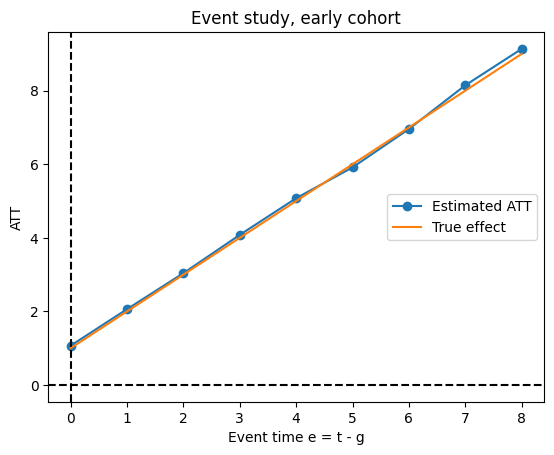

   e    att
0 -3  0.081
1 -2 -0.049


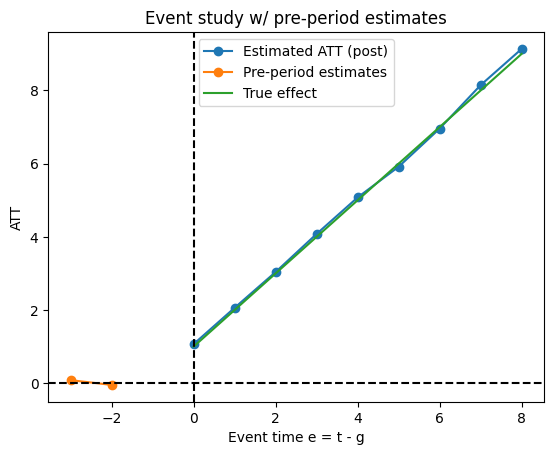

In [30]:
# YOUR TASK — optional: plot the event study, then add the early cohort's pre-period estimates
es = dd.event_study(cells)
growth = 1.0
e_true = np.arange(0, es['e'].max() + 1)

fix, ax = plt.subplots()
ax.plot(es['e'], es['att'], marker='o', label='Estimated ATT')
ax.plot(e_true, growth * (e_true + 1), label='True effect')
ax.axvline(0, color='k', linestyle='--')
ax.axhline(0, color='k', linestyle='--')
ax.set_xlabel('Event time e = t - g')
ax.set_ylabel('ATT')
ax.set_title('Event study, early cohort')
ax.legend()
plt.show()

base = g_early - 1
pre_rows = []
for t in [0, 1]:
  att = (early[t] - early[base]) - (late[t] - late[base])
  pre_rows.append({'e': t - g_early, 'att': att})
pre_es = pd.DataFrame(pre_rows)
print(pre_es.round(3))

fix, ax = plt.subplots()
ax.plot(es['e'], es['att'], marker='o', label='Estimated ATT (post)')
ax.plot(pre_es['e'], pre_es['att'], marker='o', label='Pre-period estimates')
ax.plot(e_true, growth * (e_true + 1), label='True effect')
ax.axvline(0, color='k', linestyle='--')
ax.axhline(0, color='k', linestyle='--')
ax.set_xlabel('Event time e = t - g')
ax.set_ylabel('ATT')
ax.set_title('Event study w/ pre-period estimates')
ax.legend()
plt.show()

### Interpretation Questions

1. The single-number ATT and the event study can both be "right" and tell different stories. Say what each is for, and which you would put in an abstract.
2. Your pre-period estimates come out near zero. Write the sentence you would put in a paper describing what that does and does not establish.
3. TWFE gave a negative number for a set of uniformly positive effects. Having seen the event study, explain why the failure grows with the length of the post-period for the early cohort.
4. Clustering by state worked in Diagnosis 3 with 20 states, though the state-clustered test still rejected a true null in 10% of simulated panels. Chapter 7 warned about few clusters. At what point would clustering itself stop being trustworthy, and what would you reach for instead?

1. The single-number ATT summarizes the average effect on the treated, which is useful for a headline magnitude or cost-benefit comparison. The event study shows how the effect evolved with time since treatment and whther the pre-period looks flat, which is what is needed to judge credibility and dynamics. I would put the single number in the abstract, with the dynamics in a clause, because a lone average here hides that the effect rises from 1 to 9 and covers only periods the design can identify.
2. Estimated pre-treatment differences are small and statistically indistinguishable from zero, which is consistent with parallel trends before treatment but does not establish that trends would have stayed parallel after, and the test has limited power with only two noisy pre-periods.
3. THe forbidden comparison used the early cohort as the control for the late cohort, and the early cohort's outcome keeps rising with its own effect, which grows by 1 per period. The longer the early cohort has been treated, the larger that built-in rise, so the control's change is more contaminated and the late cohort looks worse in comparison. The forbidden two-by-two also gains weight as the late cohort's treated share grows. Both the size of the contamination and its weight increase with post-period length, which is how uniformly positive effects produce a negative coefficient. A flat and constant effect would produce no failure.
4. Cluster-robust standard errors rely on the number of clusters being large, and usually they become unreliable below around 30 to 50 clusters. They get worse still when clusters are unbalanced in size, or when treatment is concentrated in a few clusters, because then the effective number of clusters is the treated count rather than the total. At that point I'd reach for a wild cluster bootstrap, t-dist critical values with G - 1 degrees of freedom, or randomization inference, which permutes treatment assignment across clusters to get an exact p-value without relying on asymptotics.

---

## Challenge (Take-Home): Honest Bounds

The challenge is optional and ungraded.

Rambachan and Roth (2023) replace "assume parallel trends" with "assume the post-treatment
violation is no larger than some multiple of what we observed pre-treatment", and report the
range of effects consistent with that.

In [31]:
# YOUR TASK — optional, ungraded: take-home Challenge, bound the estimate instead of asserting the assumption

# Step 1: take Diagnosis 1's panel, where the true effect is zero and the
#   pre-trends diverge. Measure the pre-period difference in slopes.
gap = panel.groupby(['t', 'treated'])['y'].mean().unstack()
gap = gap[1] - gap[0] # treated-minus-control gap by period
pre_jumps = gap.loc[:T_PRE - 1].diff().dropna().abs() # period-to-period change in the gap, pre only
max_jump = pre_jumps.max()  # largest pre-period divergence per period
print(f"max pre-period jump = {max_jump:.3f}")

# point estimate and standard error (baseline = last pre period, t = 5)
u = panel.pivot(index='unit', columns='t', values='y')
change = u.loc[:, T_PRE:].sub(u[T_PRE - 1], axis=0).mean(axis=1)
tr = panel.groupby('unit')['treated'].first()
a, b = change[tr == 1], change[tr == 0]
est = a.mean() - b.mean()
se = np.sqrt(a.var() / len(a) + b.var() / len(b))
print(f"point estimate = {est:.3f}, standard error = {se:.3f}")

# Step 2: assume the post-period violation is at most M times that
#   pre-period divergence, for M in {0, 0.5, 1, 2}.
avg_h = np.arange(1, T_POST + 1).mean()
Ms = [0, 0.5, 1, 2]
for M in Ms:
    print(f"\nM = {M} bias = {M * max_jump * avg_h:.3f}")


# Step 3: for each M, report the interval of treatment effects consistent
#   with the data. Find the "breakdown" M at which zero enters the interval.
for M in Ms:
  bias = M * max_jump * avg_h
  print(f"M = {M:<4} [{est - bias - 1.96 * se:6.2f}], [{est + bias + 1.96 * se:6.2f}]")

breakdown = (est - 1.96 * se) / (max_jump * avg_h)  # M at which the interval's lower end reaches zero
print(f"Breakdown M = {breakdown:.2f}")

# Step 4: report that breakdown value as a sentence a referee could use.
#   Compare it to simply saying "the pre-trend test passed".
"""
'The estimated effect is distinguishable from zero if the post-treatment violation of parallel trends is smaller than about
0.67 times the largest pre-treatment divergence in the gap, the interval includes zero at M = 1.'

A 'pre-trend test passed' is a yes/no that depends on power. The breakdown value says how wrong parallel trends can be before the conclusion
fails, so a referee can judge whether that much drift is realistic. Here the pre-trend test just fails, and the breakdown of 0.67 agrees that
the result is fragile.
"""

# Step 5: apply the same logic to Card & Krueger. C&K have only two periods,
#   so there is no pre-trend to measure. Say what that implies, and what
#   the 1994 paper offered instead as a defence of the design.
"""
With one pre-period and one post-period, there is no pre-period change in the gap, so max_jump is undefined and M can't be
calibrated from the data. Any bound would need an outside benchmark, like NJ-PA trend difference in other years.
The 1994 paper offered plausibility arguments instead. Its main one was a second comparison in New Jersey, where
restaurants already paying $5.05 or more were barely affected, so that serves as controls for lower wage restaurants, giving a dose-response
pattern. It also used only eastern Pennsylvania, alternative specifications, and payroll data. None of these tests parallel trends after increase.
"""

max pre-period jump = 0.226
point estimate = 0.636, standard error = 0.056

M = 0 bias = 0.000

M = 0.5 bias = 0.396

M = 1 bias = 0.791

M = 2 bias = 1.582
M = 0    [  0.53], [  0.75]
M = 0.5  [  0.13], [  1.14]
M = 1    [ -0.26], [  1.54]
M = 2    [ -1.06], [  2.33]
Breakdown M = 0.67


---
## Digital Portfolio: your README

### Your README prompt
Copy and paste the prompt below into Claude or ChatGPT. **Do NOT ask the AI to write Python code — only documentation.** Replace every `[YOUR VALUE]` with the number from your own output before you paste it.

```
I need help writing a project description for my data science lab.
**Important Rule:** Do NOT generate any Python code for me.

**What I did in this lab:**
* Reproduced Card and Krueger's (1994) minimum-wage difference-in-differences
  from David Card's original data files: [YOUR VALUE] full-time-equivalent
  employees, against their published +2.76
* Diagnosed a significant DiD estimate on a panel where the true effect was
  zero, caused by groups on different trends, and ran the pre-trend test
* Showed two-way fixed effects returning [YOUR VALUE] on a staggered-adoption
  panel where the true mean effect was 6.71, and took it apart into two
  two-by-two comparisons: [YOUR VALUE] of the weight sat on the one that uses
  already-treated units as controls
* Showed that iid standard errors were [YOUR VALUE] times too small on a
  panel with state shocks that persist from period to period
* Had an AI write a Goodman-Bacon decomposition and checked it against my own
  numbers, revising my prompt once; its weighted sum on a panel with missing
  outcomes was [YOUR VALUE] after the revision

**Please write a README.md entry including:**
1. Project Title: Difference-in-Differences: Parallel Trends, Staggered Adoption and the Forbidden Comparison
2. Objective: one sentence
3. Methodology: Bullet points of technical steps
4. Key Findings: Summary of results
Write it plainly, in the first person. No words like 'robust',
'comprehensive' or 'leverage'. Use only the numbers I gave you.
```

---

## Submit this lab on GitHub

**Repository name for this lab:** `econ5200-lab11-did`

**First time?** Read the **GitHub Setup and Repository Guide** page in the Start Here module once,
start to finish. It assumes you have never used git and never seen GitHub.

1. On [github.com](https://github.com): **+** (top right) → **New repository**.
   Name it exactly `econ5200-lab11-did`, tick **Add a README file**, and create it.
2. In Colab: **File → Save a copy in GitHub**. Choose `econ5200-lab11-did`, branch `main`,
   commit message `Lab 11 submission`. This pushes the notebook, and the
   notebook's rendered output — charts included — is what is graded.
3. Open the repo on github.com, click `README.md`, then the pencil icon, and
   paste in the README you drafted from the README prompt above. **Commit
   changes.** Check every number in it against your own output first: this
   goes out under your name.
4. On Canvas: in Colab use **File → Download → Download .ipynb**, upload that
   file to the assignment, and paste your repository URL in the **Comments**
   box beside the upload. Then click **Submit**. Do not use the Website URL
   tab: Canvas keeps one submission, so a URL sent on its own replaces your
   notebook.

No terminal, no token, nothing to install.